In [41]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Flatten
from tensorflow.keras.optimizers import SGD
import pandas as pd

In [42]:
train_data=pd.read_csv(r"F:\lp4\LP IV Updated Datasets\FNN and CNN\Sign Language MNIST\sign_mnist_train.csv")

test_data=pd.read_csv(r"F:\lp4\LP IV Updated Datasets\FNN and CNN\Sign Language MNIST\sign_mnist_test.csv")

In [43]:
print(train_data.shape)
print(test_data.shape)

print(train_data.head())
print(train_data.columns)

(27455, 785)
(7172, 785)
   label  pixel1  pixel2  pixel3  pixel4  pixel5  ...  pixel779  pixel780  pixel781  pixel782  pixel783  pixel784
0      3     107     118     127     134     139  ...       206       206       206       204       203       202
1      6     155     157     156     156     156  ...        94       163       175       103       135       149
2      2     187     188     188     187     187  ...       198       199       198       195       194       195
3      2     211     211     212     212     211  ...       230       226       225       222       229       163
4     13     164     167     170     172     176  ...       133       163       157       163       164       179

[5 rows x 785 columns]
Index(['label', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6',
       'pixel7', 'pixel8', 'pixel9',
       ...
       'pixel775', 'pixel776', 'pixel777', 'pixel778', 'pixel779', 'pixel780',
       'pixel781', 'pixel782', 'pixel783', 'pixel784'],
      dt

In [44]:
y_train=train_data['label']
x_train=train_data.drop('label',axis=1)

y_test=test_data['label']
x_test=test_data.drop('label',axis=1)

In [45]:
print(x_train.shape)
print(y_train.shape)

print(x_test.shape)
print(y_test.shape)

(27455, 784)
(27455,)
(7172, 784)
(7172,)


In [46]:
np.unique(y_train)


array([ 0,  1,  2,  3,  4,  5,  6,  7,  8, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24])

In [47]:
# Reshape images into 28x28


x_train=x_train.values.reshape(-1,28,28)
x_test=x_test.values.reshape(-1,28,28)

x_train=x_train.astype('float32')/255.0
x_test=x_test.astype('float32')/255.0


In [48]:
print(x_train.shape)
print(x_test.shape)

(27455, 28, 28)
(7172, 28, 28)


In [49]:
model=Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128,activation='relu'),
    Dense(64,activation='relu'),
    Dense(25,activation='softmax')
])

C:\Users\Admin\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [50]:
model.compile(
    optimizer='Adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [51]:
history=model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/11
194/194 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.2636 - loss: 2.5292 - val_accuracy: 0.4487 - val_loss: 1.8799
Epoch 2/11
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5080 - loss: 1.6123 - val_accuracy: 0.5168 - val_loss: 1.4705
Epoch 3/11
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6185 - loss: 1.2429 - val_accuracy: 0.6107 - val_loss: 1.1514
Epoch 4/11
194/194 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.6837 - loss: 1.0178 - val_accuracy: 0.6792 - val_loss: 0.9701
Epoch 5/11
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.7397 - loss: 0.8396 - val_accuracy: 0.7556 - val_loss: 0.7930
Epoch 6/11
194/194 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.7935 - loss: 0.6886 - val_accuracy: 0.8296 - val_loss: 0.6074
Epoch 7/11
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8276 - loss: 0.5805 - val_accuracy: 0.7520 - val_loss: 0.7419
Epoch 8/11
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8503 - loss: 0.5080 - val_accuracy

In [52]:
test_loss,test_accuracy=model.evaluate(x_test,y_test)
print(test_loss)
print(test_accuracy)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6974 - loss: 1.0392
1.0392358303070068
0.6974344849586487


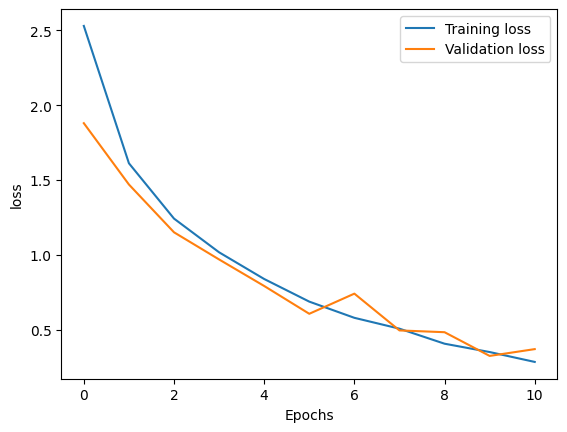

In [55]:
plt.plot(history.history['loss'],label='Training loss')
plt.plot(history.history['val_loss'],label='Validation loss')
plt.xlabel('Epochs')
plt.ylabel('loss')
plt.legend()
plt.show()

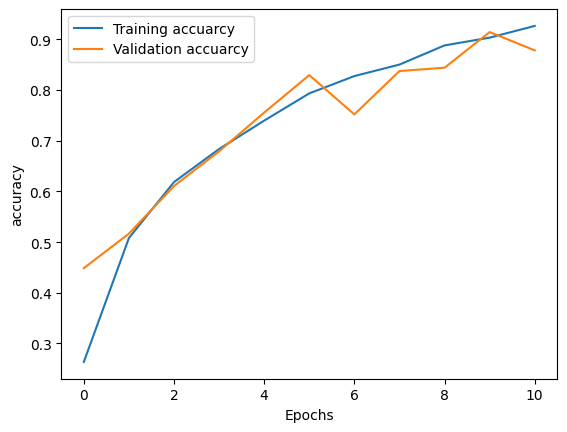

In [57]:
plt.plot(history.history['accuracy'],label='Training accuarcy')
plt.plot(history.history['val_accuracy'],label='Validation accuarcy')
plt.xlabel('Epochs')
plt.ylabel('accuracy')
plt.legend()
plt.show()